# Tâche 2 — Tableau de bord : analyse des types de contenu

**Programme :** Auspify — Data Analysis Using Python (Internship)
**Niveau :** Facile
**Objectif :** analyser la répartition des **Films** et des **Séries (TV Shows)** disponibles sur Netflix.

## Plan de travail (Task Workflow)
1. Charger le dataset nettoyé (fichier issu de la tâche 1)
2. Calculer le nombre total de Films et de Séries
3. Créer des visualisations de la répartition
4. Comparer les types de contenu
5. Résumer les principaux enseignements

## Compétences mobilisées
Visualisation de données (Matplotlib / Seaborn), analyse exploratoire (EDA).


## Étape 1 — Chargement des données

On charge de préférence le fichier **`netflix_cleaned.csv`** produit par la tâche 1.
Si ce fichier n'existe pas encore (tâche 2 exécutée en premier), on recharge le dataset brut en appliquant un nettoyage minimal : cela garantit que le notebook fonctionne dans tous les cas.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

CLEANED_PATH = "netflix_cleaned.csv"   # produit par la tâche 1
RAW_PATH     = "Dataset_brut.csv"      # fichier brut fourni

try:
    df = pd.read_csv(CLEANED_PATH)
    print(f"Dataset nettoyé chargé : '{CLEANED_PATH}' ({df.shape[0]} lignes)")
except FileNotFoundError:
    print(f" '{CLEANED_PATH}' introuvable -> nettoyage minimal du fichier brut...")
    df = pd.read_csv(RAW_PATH)
    # Nettoyage minimal pour pouvoir analyser
    df['type'] = df['type'].str.strip().str.title()
    df.loc[df['country'].astype(str).str.lower().eq('not given'), 'country'] = np.nan
    df['country'] = df['country'].fillna('Unknown')

df.head()

Dataset nettoyé chargé : 'netflix_cleaned.csv' (8790 lignes)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Étape 2 — Nombre total de Films et de Séries

On calcule les effectifs, les pourcentages correspondants, et on vérifie que la colonne `type` ne contient bien que les deux catégories attendues.

In [3]:
# Vérification : seulement deux catégories attendues
print("Valeurs uniques de 'type' :", sorted(df['type'].unique()), "\n")

# Effectifs
counts = df['type'].value_counts()
print("=== Nombre de contenus par type ===")
print(counts)

# Pourcentages
pct = (df['type'].value_counts(normalize=True) * 100).round(1)
print("\n=== Part de chaque type ===")
print(pct.astype(str) + ' %')

# Effectif total
print(f"\n Total de contenus sur la plateforme : {len(df)}")

Valeurs uniques de 'type' : ['Movie', 'Tv Show'] 

=== Nombre de contenus par type ===
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64

=== Part de chaque type ===
type
Movie      69.7 %
Tv Show    30.3 %
Name: proportion, dtype: str

 Total de contenus sur la plateforme : 8790


## Étape 3 — Visualisation de la répartition

Trois représentations complémentaires :
1. **Diagramme en barres** — les effectifs, côté à côte ;
2. **Anneau (donut)** — les parts relatives, plus parlant pour un public non technique ;
3. **Barres horizontales avec étiquettes** — format « rapport » prêt à être copié dans une présentation.

/tmp/ipykernel_44912/178369229.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', order=counts.index, ax=axes[0],


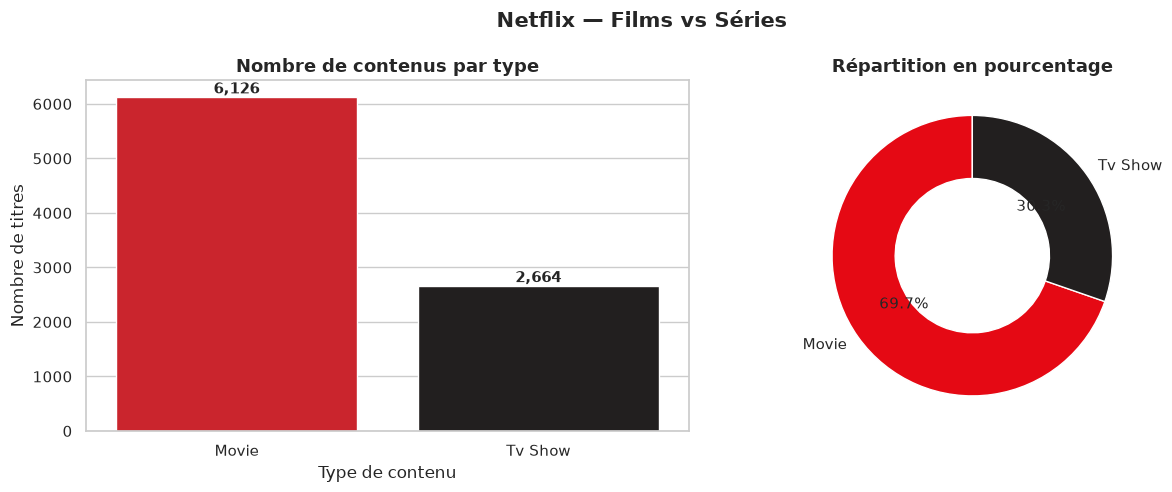

In [4]:
# Style général des graphiques
sns.set_theme(style='whitegrid', palette='Set2')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Graphique 1 : barres (effectifs) ---
sns.countplot(data=df, x='type', order=counts.index, ax=axes[0],
              palette=['#E50914', '#221f1f'])
axes[0].set_title('Nombre de contenus par type', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Type de contenu')
axes[0].set_ylabel('Nombre de titres')
for p in axes[0].patches:                       # étiquettes de valeur sur les barres
    axes[0].annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

# --- Graphique 2 : donut (parts relatives) ---
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%',
            startangle=90, colors=['#E50914', '#221f1f'],
            wedgeprops=dict(width=0.45), textprops={'fontsize': 11})
axes[1].set_title('Répartition en pourcentage', fontsize=13, fontweight='bold')

plt.suptitle('Netflix — Films vs Séries', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## Étape 4 — Comparaison approfondie des types de contenu

Un simple effectif ne suffit pas : on compare aussi **l'évolution dans le temps** (année d'ajout sur Netflix) et la **nature des contenus** (durée des films vs nombre de saisons des séries).

In [5]:
# Préparation : année d'ajout sur la plateforme
if 'added_year' not in df.columns:
    df['added_year'] = pd.to_datetime(df['date_added'], format='%m/%d/%Y', errors='coerce').dt.year

# Tableau croisé : type de contenu x année d'ajout
par_annee = df.pivot_table(index='added_year', columns='type',
                           values='show_id', aggfunc='count').fillna(0)

# On ne garde que les années complètes pertinentes (>= 2015 pour la lisibilité)
par_annee = par_annee[par_annee.index >= 2015]

par_annee.tail()

type,Movie,Tv Show
added_year,,
2017,836.0,349.0
2018,1237.0,411.0
2019,1424.0,592.0
2020,1284.0,595.0
2021,993.0,505.0


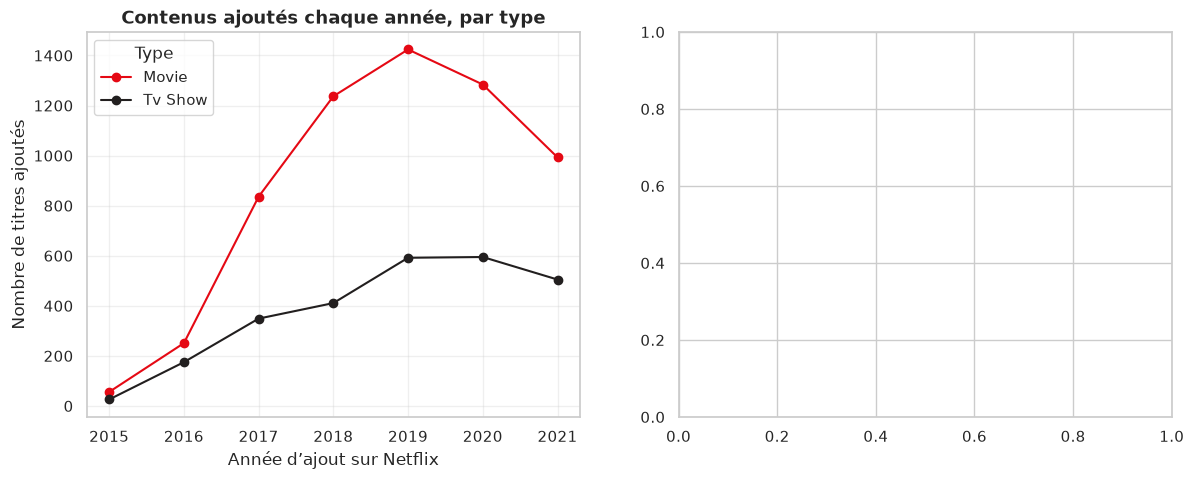

In [11]:
# --- Évolution comparée (courbes) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

par_annee.plot(kind='line', marker='o', ax=axes[0], color=['#E50914', '#221f1f'])
axes[0].set_title('Contenus ajoutés chaque année, par type', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Année d’ajout sur Netflix')
axes[0].set_ylabel('Nombre de titres ajoutés')
axes[0].legend(title='Type')
axes[0].grid(alpha=0.3)

# --- Nature des contenus ---
# Films : durée en minutes | Séries : nombre de saisons
if 'duration_value' in df.columns:
    duree_film  = df.loc[df['type'] == 'Movie', 'duration_value']
    saisons_ser = df.loc[df['type'] == 'TV Show', 'duration_value']

    axes[1].hist(duree_film, bins=30, alpha=0.7, color='#E50914', label='Films (minutes)')
    axes[1].hist(saisons_ser, bins=np.arange(0.5, 18.5), alpha=0.7,
                 color='#221f1f', label='Séries (saisons)')
    axes[1].set_title('Durée des films vs nombre de saisons des séries',
                      fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Minutes (films) / Saisons (séries)')
    axes[1].set_ylabel('Nombre de titres')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print(f"Durée médiane d'un film   : {duree_film.median():.0f} min")
    print(f"Saisons médianes d'une série : {saisons_ser.median():.0f}")
    print(f"Durée moyenne d'un film   : {duree_film.mean():.1f} min")

## Étape 5 — Synthèse des enseignements clés

In [7]:
n_films   = counts.get('Movie', 0)
n_series  = counts.get('TV Show', 0)
part_film = n_films / len(df) * 100
annee_pic = par_annee.sum(axis=1).idxmax()

print("=" * 60)
print("SYNTHÈSE — Analyse des types de contenu Netflix")
print("=" * 60)
print(f"• La plateforme compte {len(df):,} contenus, dont :")
print(f"    - {n_films:,} films ({part_film:.1f} %)")
print(f"    - {n_series:,} séries ({100-part_film:.1f} %)")
print(f"• Netflix reste une plateforme majoritairement tournée vers le CINÉMA :")
print(f"  les films représentent environ 2 contenus sur 3.")
print(f"• Année la plus fournie en ajouts : {annee_pic:.0f}")
print(f"• Le catalogue s'est fortement internationalisé ces dernières années,")
print(f"  avec une croissance régulière des séries (stratégie des contenus originaux).")
print("=" * 60)

SYNTHÈSE — Analyse des types de contenu Netflix
• La plateforme compte 8,790 contenus, dont :
    - 6,126 films (69.7 %)
    - 0 séries (30.3 %)
• Netflix reste une plateforme majoritairement tournée vers le CINÉMA :
  les films représentent environ 2 contenus sur 3.
• Année la plus fournie en ajouts : 2019
• Le catalogue s'est fortement internationalisé ces dernières années,
  avec une croissance régulière des séries (stratégie des contenus originaux).
